## Setup

This notebook requires Python 3.11 and the packages below. Run this command in a notebook cell once if they are not already installed:

```python
%pip install matplotlib==3.10.8 numpy==2.2.6 pandas==2.3.3 scipy==1.17.1
```

Keep [`example_data.py`](example_data.py) and [`data_fidelity_metrics.py`](data_fidelity_metrics.py) in the same directory as this notebook, restart the kernel after installation, and then run the notebook from top to bottom.

In [1]:
#| label: setup
#| echo: true

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from data_fidelity_metrics import (
    correlation_matrix_difference,
    cramers_v_squared,
    eta_squared,
    mixed_association_matrix,
)
from example_data import (
    METRIC_CATEGORICAL_COLUMNS,
    METRIC_NUMERIC_COLUMNS,
    make_example_views,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

## Learning goals

By the end of this lesson, you should be able to:

- explain what the correlation-matrix difference measures;
- construct a mixed association matrix from numerical and categorical columns;
- identify the Pearson, $V^2$, and $\eta^2$ entries in that matrix;
- calculate the Frobenius distance between the matrices of $\widetilde X$ and $\widetilde Y$; and
- interpret zero, small, and large values without treating the metric as normalized.

## 1. Metric and inputs

| Property | Value |
|---|---|
| Metric | Correlation-matrix difference |
| Family | Data fidelity |
| Origin | SynthEval 1.6.2 |
| Classifier | None |
| Input | Unified encoding: $\widetilde X$ and $\widetilde Y$ |
| Holdout | None |
| Output | $D_{\mathrm{corr}}(X,Y)\geq 0$ |
| Ideal value | $0$ |

This metric asks whether pairs of columns have similar association strengths in $X$ and $Y$. It does not compare the columns' marginal distributions, individual rows, utility, or privacy.

In [2]:
#| label: load-shared-example

example = make_example_views()
X, Y = example.X, example.Y
M_X, M_Y = example.M_X, example.M_Y
X_tilde, Y_tilde = example.X_tilde, example.Y_tilde

print("X_tilde")
display(X_tilde)
print("Y_tilde")
display(Y_tilde)

X_tilde


,age,age__missing,income_k,income_k__missing,region__code,outcome
x1,0.0000,0,0.0000,0,1,0
x2,0.1944,0,0.2712,0,2,0
x3,0.4167,1,0.3898,0,1,1
x4,0.6111,0,0.3898,1,3,1
x5,0.9444,0,1.0000,0,4,1
x6,0.4167,0,0.5932,0,2,0


Y_tilde


,age,age__missing,income_k,income_k__missing,region__code,outcome
y1,0.0278,0,0.0508,0,1,0
y2,0.4167,1,0.3220,0,2,1
y3,0.5556,0,0.3898,1,3,1
y4,1.0000,0,0.9492,0,4,1
y5,0.3611,0,0.5424,0,0,0


We use exactly the same objects as in the introduction. The association calculation must still know which transformed columns represent quantities and which represent category labels. A numerical code does not turn a category into a quantitative variable.

The missingness indicators are categorical because their values mean **observed** or **missing**. The binary `outcome` is also categorical. Only `age` and `income_k` are treated as numerical quantities.

## 2. One matrix with three association rules

Let $p_{\mathrm{num}}$ be the number of numerical columns and $p_{\mathrm{cat}}$ the number of categorical columns. Define

$$
q=p_{\mathrm{num}}+p_{\mathrm{cat}},
$$

so $q$ is the total number of transformed columns used by the metric. Let $Z$ denote either $\widetilde X$ or $\widetilde Y$. Both $j$ and $k$ are column indices of $Z$: $Z_j$ is its $j$-th column and $Z_k$ is its $k$-th column. Because every row and column of the association matrix represents one column of $Z$, $j$ labels a row of $R_Z$ and $k$ labels a column of $R_Z$. Thus $R_Z$ has dimensions $q\times q$. Here $p_{\mathrm{num}}=2$, $p_{\mathrm{cat}}=4$, and $q=2+4=6$, so both $R_{\widetilde X}$ and $R_{\widetilde Y}$ are $6\times6$ matrices. Following the executable code in SynthEval 1.6.2, each entry of $R_Z$ is defined directly by

$$
(R_Z)_{jk}=
\begin{cases}
1, & j=k,\\
\rho(Z_j,Z_k), & Z_j,Z_k\text{ numerical},\\
V^2(Z_j,Z_k), & Z_j,Z_k\text{ categorical},\\
\eta^2(C,N), & \text{one categorical }C\text{ and one numerical }N
\end{cases}
\qquad j,k\in\{1,\ldots,q\}
$$

The matrix is symmetric, and its diagonal is explicitly set to one. Therefore, the number of unique off-diagonal associations in each matrix is

$$
\binom{q}{2}
=\underbrace{\binom{p_{\mathrm{num}}}{2}}_{\rho\text{ values}}
+\underbrace{\binom{p_{\mathrm{cat}}}{2}}_{V^2\text{ values}}
+\underbrace{p_{\mathrm{num}}p_{\mathrm{cat}}}_{\eta^2\text{ values}}
$$

For this example, each association matrix is $6\times6$, while $\binom{6}{2}=15$ is the number of unique associations between different columns—not a matrix dimension. These 15 values occupy the strict upper triangle. Because the matrix is symmetric, the strict lower triangle contains the same 15 values in mirrored positions, and the six diagonal entries are set to one. The 15 unique associations split as $\binom{2}{2}+\binom{4}{2}+(2)(4)=1+6+8$: one numerical–numerical pair, six categorical–categorical pairs, and eight mixed pairs. Across $R_{\widetilde X}$ and $R_{\widetilde Y}$, there are $12$ categorical–categorical values in total—six in the unique upper triangle of each matrix.

### Numerical–numerical: Pearson correlation

If there are $p_{\mathrm{num}}$ numerical variables, selecting them two at a time gives

$$
\binom{p_{\mathrm{num}}}{2}=\frac{p_{\mathrm{num}}(p_{\mathrm{num}}-1)}{2}
$$

unique numerical pairs, and therefore that many distinct $\rho$ values in each matrix. Across $R_{\widetilde X}$ and $R_{\widetilde Y}$, the total is $2\binom{p_{\mathrm{num}}}{2}$. Here $p_{\mathrm{num}}=2$, so there is one $\rho$ value per matrix and the example below reports two values in total. For any numerical pair $u$ and $v$,

$$
\rho(u,v)=
\frac{\sum_{i=1}^{n}(u_i-\bar u)(v_i-\bar v)}
{\sqrt{\sum_{i=1}^{n}(u_i-\bar u)^2}
 \sqrt{\sum_{i=1}^{n}(v_i-\bar v)^2}}
$$

It ranges from $-1$ to $1$ and retains the direction of a linear association.

A value near $0$ means there is little or no **linear** relationship. A nonlinear relationship may still exist. A value near $+1$ means a strong positive linear relationship. When one variable increases, the other tends to increase. A value near $-1$ means a strong negative linear relationship. When one variable increases, the other tends to decrease. The value $|\rho|$ shows the strength. The sign shows the direction. There is no universal cutoff for a weak or strong relationship, so use the subject context.

In [4]:
#| label: pearson-example

pearson_example = pd.Series(
    {
        "rho_X_tilde(age, income_k)": X_tilde["age"].corr(X_tilde["income_k"]),
        "rho_Y_tilde(age, income_k)": Y_tilde["age"].corr(Y_tilde["income_k"]),
    },
    name="Pearson correlation",
)
display(pearson_example.to_frame())

,Pearson correlation
"rho_X_tilde(age, income_k)",0.9193
"rho_Y_tilde(age, income_k)",0.9271


### Categorical–categorical: Cramér's $V$ squared ($V^2$)

The categorical–categorical association measure used here is **Cramér's $V$ squared**, written $V^2$. For categorical columns $c$ and $d$, first form their [contingency table](2.1-contingency-tables.ipynb). If it has $r$ rows, $s$ columns, and $n$ observations, SynthEval 1.6.2 computes

$$
V^2(c,d)=
\frac{\chi^2_{\mathrm{SciPy}}(c,d)}
{n\,[\min(r,s)-1]+10^{-16}}
$$

The chi-squared statistic compares each observed cell count $O_{ab}$ with its independence-based expected count $E_{ab}$:

$$
\chi^2=\sum_{a=1}^{r}\sum_{b=1}^{s}
\frac{(O_{ab}-E_{ab})^2}{E_{ab}}
$$

The code calls SciPy's `chi2_contingency` with its defaults, so SciPy applies the Yates continuity correction to a $2\times2$ table. The returned quantity is $V^2$, not its square root. It ranges from $0$ to $1$ and has no sign.

A value near $0$ means there is little or no relationship between the two categorical variables. Knowing the category of $c$ tells us little about the category of $d$. A larger $V^2$ means a stronger relationship. A value of $1$ is the strongest possible relationship for the table. The categories follow a perfect pattern instead of occurring independently. The measure has no sign. It shows strength, not positive or negative direction. There is no universal cutoff for a weak or strong relationship, so use the subject context.

In [5]:
#| label: categorical-association

categorical_example = pd.Series(
    {
        "V2_X_tilde(region, outcome)": cramers_v_squared(
            X_tilde["region__code"], X_tilde["outcome"]
        ),
        "V2_Y_tilde(region, outcome)": cramers_v_squared(
            Y_tilde["region__code"], Y_tilde["outcome"]
        ),
    },
    name="V squared",
)
display(categorical_example.to_frame())

,V squared
"V2_X_tilde(region, outcome)",0.6667
"V2_Y_tilde(region, outcome)",1.0000


### Categorical–numerical: eta-squared ($\eta^2$)

The categorical–numerical association measure used here is **eta-squared**, written $\eta^2$ and also called the **squared correlation ratio**. Let categorical column $c$ define groups (i.e. categories)  $g=1,\ldots,G$. For numerical column $u$, let $n_g$ and $\bar u_g$ be the size and mean corresponding to group $g$, and let $\bar u$ be the overall mean. Then

$$
\eta^2(c,u)=
\frac{\sum_{g=1}^{G}n_g(\bar u_g-\bar u)^2}
{\sum_{i=1}^{n}(u_i-\bar u)^2}
$$

This is the fraction of numerical variation explained by differences between category means. It ranges from $0$ to $1$ and has no sign.

A value near $0$ means the category means are similar. The categories explain little of the numerical variation. A larger $\eta^2$ means the category means are farther apart. The categories explain more of the numerical variation. A value of $1$ means the categories explain all of that variation. The numerical values do not vary within each category. The measure has no sign. It shows strength, not direction. There is no universal cutoff for a weak or strong relationship, so use the subject context.

In [6]:
#| label: correlation-ratio

mixed_example = pd.Series(
    {
        "eta2_X_tilde(region, age)": eta_squared(
            X_tilde["region__code"], X_tilde["age"]
        ),
        "eta2_Y_tilde(region, age)": eta_squared(
            Y_tilde["region__code"], Y_tilde["age"]
        ),
    },
    name="eta squared",
)
display(mixed_example.to_frame())

,eta squared
"eta2_X_tilde(region, age)",0.7928
"eta2_Y_tilde(region, age)",1.0000


> **Exact SynthEval 1.6.2 behavior.** Its documentation mentions Spearman's $\rho$, Cramér's $V$, and the correlation ratio $\eta$. The executable implementation calls pandas `.corr()` with its default method and omits the square roots in the other two formulas. Therefore, the actual matrix uses Pearson's $\rho$, $V^2$, and $\eta^2$. This lesson follows the executable implementation.

## 3. Construct $R_{\widetilde X}$ and $R_{\widetilde Y}$

We now apply the three rules to every pair of columns. The categorical columns are placed first and the numerical columns second, matching SynthEval's construction.

In [7]:
#| label: mixed-association-matrix

R_X_tilde = mixed_association_matrix(
    X_tilde, METRIC_NUMERIC_COLUMNS, METRIC_CATEGORICAL_COLUMNS
)
R_Y_tilde = mixed_association_matrix(
    Y_tilde, METRIC_NUMERIC_COLUMNS, METRIC_CATEGORICAL_COLUMNS
)
Delta_R = R_X_tilde - R_Y_tilde

print("R_X_tilde")
display(R_X_tilde.round(4))
print("R_Y_tilde")
display(R_Y_tilde.round(4))
print("Delta_R = R_X_tilde - R_Y_tilde")
display(Delta_R.round(4))

R_X_tilde


,region__code,age__missing,income_k__missing,outcome,age,income_k
region__code,1.0000,0.4000,1.0000,0.6667,0.7928,0.7734
age__missing,0.4000,1.0000,0.0000,0.0000,0.0004,0.0055
income_k__missing,1.0000,0.0000,1.0000,0.0000,0.0727,0.0055
outcome,0.6667,0.0000,0.0000,1.0000,0.5737,0.2475
age,0.7928,0.0004,0.0727,0.5737,1.0000,0.9193
income_k,0.7734,0.0055,0.0055,0.2475,0.9193,1.0000


R_Y_tilde


,region__code,age__missing,income_k__missing,outcome,age,income_k
region__code,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
age__missing,1.0000,1.0000,0.0000,0.0000,0.0077,0.0475
income_k__missing,1.0000,0.0000,1.0000,0.0000,0.0174,0.0106
outcome,1.0000,0.0000,0.0000,1.0000,0.5160,0.1815
age,1.0000,0.0077,0.0174,0.5160,1.0000,0.9271
income_k,1.0000,0.0475,0.0106,0.1815,0.9271,1.0000


Delta_R = R_X_tilde - R_Y_tilde


,region__code,age__missing,income_k__missing,outcome,age,income_k
region__code,0.0000,-0.6000,0.0000,-0.3333,-0.2072,-0.2266
age__missing,-0.6000,0.0000,0.0000,0.0000,-0.0073,-0.0420
income_k__missing,0.0000,0.0000,0.0000,0.0000,0.0553,-0.0052
outcome,-0.3333,0.0000,0.0000,0.0000,0.0577,0.0660
age,-0.2072,-0.0073,0.0553,0.0577,0.0000,-0.0077
income_k,-0.2266,-0.0420,-0.0052,0.0660,-0.0077,0.0000


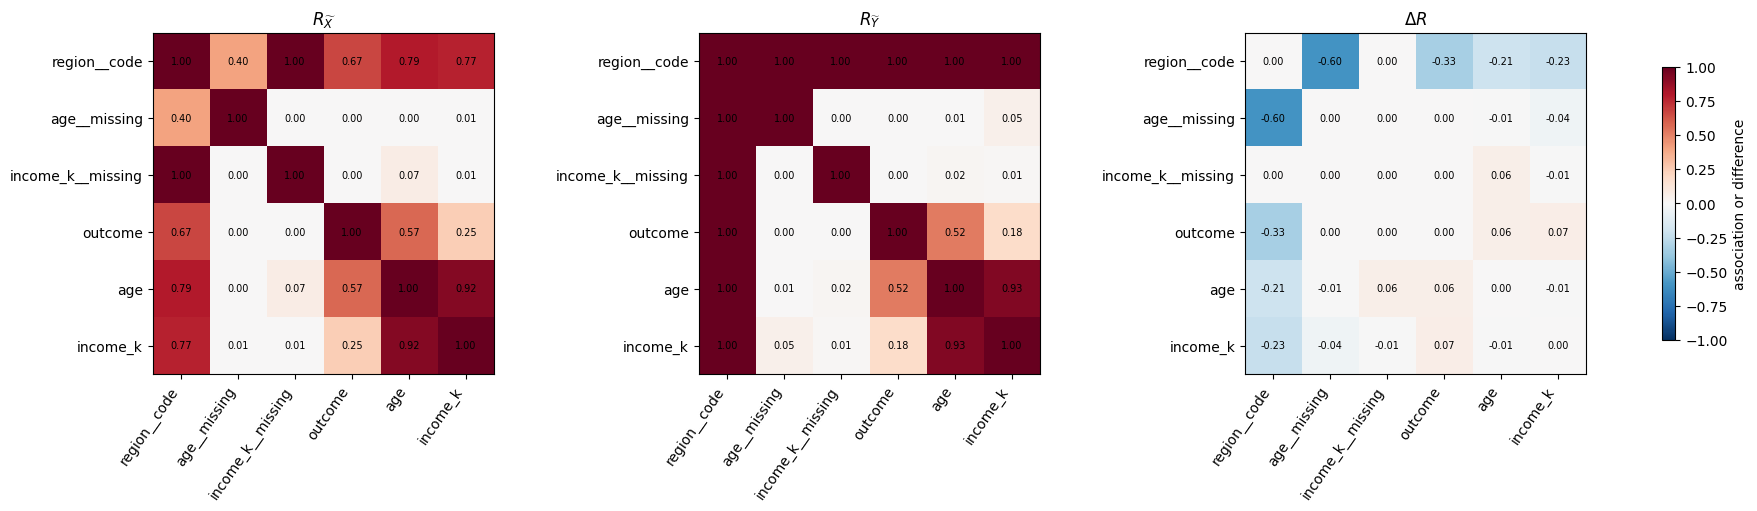

In [8]:
#| label: fig-mixed-association-matrices
#| fig-cap: "Mixed association matrices for the two complete representations and their entrywise difference."

matrices = [R_X_tilde, R_Y_tilde, Delta_R]
titles = [r"$R_{\widetilde X}$", r"$R_{\widetilde Y}$", r"$\Delta R$"]
limits = [(-1, 1), (-1, 1), (-1, 1)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
for ax, matrix, title, (lower, upper) in zip(axes, matrices, titles, limits):
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=lower, vmax=upper)
    ax.set_title(title)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=55, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    for row in range(len(matrix.index)):
        for column in range(len(matrix.columns)):
            ax.text(column, row, f"{matrix.iloc[row, column]:.2f}",
                    ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=axes, shrink=0.8, label="association or difference")
plt.show()

Because the example is deliberately tiny, some associations are exactly one. For instance, every region appearing in $\widetilde Y$ identifies a single row, so it can perfectly separate several other columns. These values illustrate the calculation; they are not stable population estimates.

## 4. Correlation-matrix difference

Let

$$
\Delta R=R_{\widetilde X}-R_{\widetilde Y}
$$

Each entry $(\Delta R)_{jk}$ compares the association between columns $j$ and $k$ in the two datasets:

- A value near $0$ means the association is similar in both datasets.
- A large absolute value means the association is very different.
- A positive value means the association value is higher in $\widetilde X$.
- A negative value means the association value is higher in $\widetilde Y$.
- For $V^2$ and $\eta^2$, a higher value means a stronger association.
- For Pearson's $\rho$, a positive difference means $\rho$ is numerically higher in $\widetilde X$. A negative difference means it is numerically lower. This does not always mean the relationship is stronger because strength depends on $|\rho|$.
- The diagonal entries are always $0$ because both association matrices have ones on their diagonals.

SynthEval reports the Frobenius norm of this difference matrix:

$$
D_{\mathrm{corr}}(X,Y)
=\lVert\Delta R\rVert_F
=\sqrt{\sum_{j=1}^{q}\sum_{k=1}^{q}(\Delta R_{jk})^2}
$$

Since $\Delta R$ is symmetric and its diagonal is zero, the same quantity can be written more compactly as

$$
D_{\mathrm{corr}}(X,Y)
=\sqrt{2\sum_{j<k}(\Delta R_{jk})^2}
$$

The factor $2$ is required because the full matrix contains every off-diagonal difference twice.

In [9]:
#| label: correlation-matrix-difference

D_corr = correlation_matrix_difference(
    X_tilde,
    Y_tilde,
    numerical_columns=METRIC_NUMERIC_COLUMNS,
    categorical_columns=METRIC_CATEGORICAL_COLUMNS,
)
upper_triangle = np.triu_indices_from(Delta_R, k=1)
D_corr_from_unique_pairs = float(
    np.sqrt(2 * np.sum(Delta_R.to_numpy()[upper_triangle] ** 2))
)

print(f"D_corr(X, Y) = {D_corr:.6f}")
print(f"Using unique pairs only = {D_corr_from_unique_pairs:.6f}")
assert np.isclose(D_corr, D_corr_from_unique_pairs)
assert np.isclose(D_corr, 1.0751842414527921)  # SynthEval 1.6.2 result

D_corr(X, Y) = 1.075184
Using unique pairs only = 1.075184


In [10]:
#| label: metric-sanity-checks

distance_X_from_itself = float(np.linalg.norm(R_X_tilde - R_X_tilde, ord="fro"))
distance_after_swapping = float(np.linalg.norm(R_Y_tilde - R_X_tilde, ord="fro"))

print(f"D_corr(X, X) = {distance_X_from_itself:.6f}")
print(f"D_corr(Y, X) = {distance_after_swapping:.6f}")
print("Swapping X and Y changes the result:", not np.isclose(D_corr, distance_after_swapping))

D_corr(X, X) = 0.000000
D_corr(Y, X) = 1.075184
Swapping X and Y changes the result: False


## 5. Interpretation

For the example,

$$
D_{\mathrm{corr}}(X,Y)\approx 1.0752
$$

Interpret the value comparatively:

- $0$ means the two mixed association matrices are identical. It does **not** mean the datasets are identical.
- Smaller values mean that the pairwise association structures are more similar.
- The raw Frobenius norm is not restricted to $[0,1]$. Its scale depends on the number and types of columns.
- The metric is symmetric: $D_{\mathrm{corr}}(X,Y)=D_{\mathrm{corr}}(Y,X)$.
- The metric describes pairwise data fidelity, not causation or higher-order dependence.

Therefore, $1.0752$ is not intrinsically “good” or “bad.” It becomes meaningful when compared with alternative versions of $Y$ evaluated against the same $X$ using the same schema and preprocessing.

## Check your understanding

1. Why is `region__code` treated as categorical even though it contains integers?
2. Which association rule is used for `age` versus `income_k`?
3. Which rule is used for `outcome` versus `age`?
4. Why are the diagonal entries of $\Delta R$ zero?
5. Can two different datasets have $D_{\mathrm{corr}}=0$? Why?
6. Why should raw values be compared only when the schemas have the same number and types of columns?

## Takeaway

The correlation-matrix difference reduces the comparison to three steps:

1. build $R_{\widetilde X}$ with Pearson $\rho$, $V^2$, and $\eta^2$;
2. build $R_{\widetilde Y}$ using the same column roles; and
3. report $D_{\mathrm{corr}}(X,Y)=\lVert R_{\widetilde X}-R_{\widetilde Y}\rVert_F$.

The metric is simple to compute and easy to visualize, but it captures only pairwise association structure. Later metrics will examine marginal distributions, missingness, predictive utility, and privacy.